In [1]:
# 1. Install library
!pip -q install rasterio requests pandas matplotlib numpy

In [3]:
# 2. Menghubungkan Google Drive dan menentukan area kajian
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from datetime import datetime, timedelta, timezone
from getpass import getpass

import json
import numpy as np
import pandas as pd
import requests
import rasterio
import matplotlib.pyplot as plt

from rasterio.io import MemoryFile
from rasterio.transform import from_bounds

ROOT = Path(
    "/content/drive/MyDrive/Mount_Ruang_Final_2024"
)

OUTPUT = ROOT / "04_CNN_Sentinel3"
OUTPUT.mkdir(parents=True, exist_ok=True)

VOLCANO_LON = 125.374
VOLCANO_LAT = 2.303

# Batas area: bujur minimum, lintang minimum,
# bujur maksimum, lintang maksimum.
AOI = [122.0, 0.0, 127.5, 5.0]

ERUPTION = datetime(
    2024, 4, 17, 12, 15,
    tzinfo=timezone.utc
)

SEARCH_START = "2024-04-17T00:00:00Z"
SEARCH_END = "2024-04-20T00:00:00Z"

print("Folder hasil:", OUTPUT)
print("Waktu kejadian:", ERUPTION.isoformat())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder hasil: /content/drive/MyDrive/Mount_Ruang_Final_2024/04_CNN_Sentinel3
Waktu kejadian: 2024-04-17T12:15:00+00:00


In [4]:
# 3. Autentikasi Copernicus Data Space
CLIENT_ID = getpass("Copernicus Client ID: ").strip()
CLIENT_SECRET = getpass("Copernicus Client Secret: ").strip()

TOKEN_URL = (
    "https://identity.dataspace.copernicus.eu/"
    "auth/realms/CDSE/protocol/openid-connect/token"
)

CATALOG_URL = (
    "https://sh.dataspace.copernicus.eu/"
    "api/v1/catalog/1.0.0/search"
)

PROCESS_URL = (
    "https://sh.dataspace.copernicus.eu/process/v1"
)

def get_token():
    response = requests.post(
        TOKEN_URL,
        data={
            "grant_type": "client_credentials",
            "client_id": CLIENT_ID,
            "client_secret": CLIENT_SECRET
        },
        timeout=60
    )

    if response.status_code != 200:
        raise RuntimeError(
            "Autentikasi gagal. Periksa OAuth Client ID, "
            "Client Secret, dan akses Sentinel Hub."
        )

    return response.json()["access_token"]

def auth_headers():
    return {
        "Authorization": f"Bearer {get_token()}",
        "Content-Type": "application/json"
    }

# Token tidak ditampilkan pada keluaran notebook.
get_token()
print("Autentikasi berhasil.")

Copernicus Client ID: ··········
Copernicus Client Secret: ··········
Autentikasi berhasil.


In [5]:
# 4. Mencari scene Sentinel-3 SLSTR
def search_catalog():
    payload = {
        "collections": ["sentinel-3-slstr"],
        "bbox": AOI,
        "datetime": f"{SEARCH_START}/{SEARCH_END}",
        "limit": 100
    }

    features = []

    while True:
        response = requests.post(
            CATALOG_URL,
            headers=auth_headers(),
            json=payload,
            timeout=120
        )

        if response.status_code != 200:
            raise RuntimeError(
                f"Catalog error {response.status_code}: "
                f"{response.text[:500]}"
            )

        result = response.json()
        features.extend(result.get("features", []))

        next_page = result.get("context", {}).get("next")

        if next_page is None:
            break

        payload["next"] = next_page

    return features

features = search_catalog()

if not features:
    raise RuntimeError(
        "Tidak ada scene ditemukan. Periksa periode, "
        "area kajian, atau akses koleksi."
    )

records = []

for feature in features:
    properties = feature["properties"]
    acquisition_time = properties.get("datetime")

    if acquisition_time is None:
        continue

    dt = datetime.fromisoformat(
        acquisition_time.replace("Z", "+00:00")
    )

    records.append({
        "scene_id": feature["id"],
        "acquisition_UTC": acquisition_time,
        "hours_from_eruption": round(
            (dt - ERUPTION).total_seconds() / 3600, 2
        ),
        "orbit": properties.get(
            "sat:orbit_state", "not provided"
        )
    })

catalog = pd.DataFrame(records)

if catalog.empty:
    raise RuntimeError(
        "Informasi waktu perekaman tidak tersedia."
    )

catalog = (
    catalog.sort_values("acquisition_UTC")
    .reset_index(drop=True)
)

catalog.index.name = "scene_index"

display(catalog)

catalog.to_csv(
    OUTPUT / "Sentinel3_Scene_Catalog.csv"
)

print("Jam negatif: sebelum kejadian acuan.")
print("Jam positif: setelah kejadian acuan.")

,scene_id,acquisition_UTC,hours_from_eruption,orbit
scene_index,,,,
0,S3A_SL_1_RBT____20240417T010411_20240417T01071...,2024-04-17T01:04:10.794Z,-11.18,descending
1,S3B_SL_1_RBT____20240417T020610_20240417T02091...,2024-04-17T02:06:09.813Z,-10.15,descending
2,S3A_SL_1_RBT____20240417T134205_20240417T13440...,2024-04-17T13:42:05.282Z,1.45,ascending
3,S3A_SL_1_RBT____20240417T134404_20240417T13470...,2024-04-17T13:44:04.456Z,1.48,ascending
4,S3B_SL_1_RBT____20240418T013959_20240418T01425...,2024-04-18T01:39:59.163Z,13.42,descending
5,S3A_SL_1_RBT____20240418T131753_20240418T13205...,2024-04-18T13:17:53.466Z,25.05,ascending
6,S3B_SL_1_RBT____20240418T141754_20240418T14195...,2024-04-18T14:17:53.858Z,26.05,ascending
7,S3B_SL_1_RBT____20240418T141953_20240418T14225...,2024-04-18T14:19:53.082Z,26.08,ascending
8,S3B_SL_1_RBT____20240419T011349_20240419T01164...,2024-04-19T01:13:48.599Z,36.98,descending


Jam negatif: sebelum kejadian acuan.
Jam positif: setelah kejadian acuan.


In [10]:
# 5. menentukan Ukuran Grid Sentinel-3
import numpy as np
import math

# AOI lokal awal untuk analisis Gunung Ruang
# Format: [lon_min, lat_min, lon_max, lat_max]
AOI = [124.8, 1.8, 126.0, 2.9]

# Resolusi target grid dalam meter
RESOLUTION_M = 500

# Pisahkan koordinat AOI
lon_min, lat_min, lon_max, lat_max = AOI

# Validasi parameter
assert lon_min < lon_max, "Batas longitude AOI tidak valid."
assert lat_min < lat_max, "Batas latitude AOI tidak valid."
assert RESOLUTION_M > 0, "Resolusi harus lebih besar dari nol."

# Perkiraan ukuran AOI dalam meter
mean_lat = (lat_min + lat_max) / 2

width_m = (
    (lon_max - lon_min)
    * 111320
    * math.cos(math.radians(mean_lat))
)

height_m = (
    (lat_max - lat_min)
    * 110574
)

# Hitung dimensi raster
NX = int(math.ceil(width_m / RESOLUTION_M))
NY = int(math.ceil(height_m / RESOLUTION_M))

# Tampilkan hasil
print("=" * 50)
print("GRID SENTINEL-3 — GUNUNG RUANG")
print("=" * 50)
print("AOI:", AOI)
print(f"Perkiraan lebar AOI : {width_m / 1000:.2f} km")
print(f"Perkiraan tinggi AOI: {height_m / 1000:.2f} km")
print("Resolusi target:", RESOLUTION_M, "meter")
print("NX (lebar raster):", NX)
print("NY (tinggi raster):", NY)
print("Total piksel:", NX * NY)
print("=" * 50)


GRID SENTINEL-3 — GUNUNG RUANG
AOI: [124.8, 1.8, 126.0, 2.9]
Perkiraan lebar AOI : 133.47 km
Perkiraan tinggi AOI: 121.63 km
Resolusi target: 500 meter
NX (lebar raster): 267
NY (tinggi raster): 244
Total piksel: 65148


In [28]:
# 6. Mengambil Kanal dan Menyusun Stack Sentinel-3
import json
import requests
import numpy as np
from rasterio.io import MemoryFile

# Waktu Sentinel-3 disesuaikan dengan raster SO2 tanggal 17 April
TIME_FROM = "2024-04-17T00:00:00Z"
TIME_TO   = "2024-04-18T00:00:00Z"

print("Pengamatan Sentinel-3: 17 April 2024 UTC")

required = [
    "AOI", "NX", "NY", "TIME_FROM", "TIME_TO",
    "PROCESS_URL", "auth_headers"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Jalankan cell sebelumnya. Variabel belum tersedia: "
        + ", ".join(missing)
    )

# Mencegah penggunaan stack lama jika proses baru gagal
for name in ["raw", "reflectance", "thermal", "mask_gabungan"]:
    globals().pop(name, None)


def ambil_kanal(bands, unit):
    input_bands = bands + ["dataMask"]
    input_units = [unit] * len(bands) + ["DN"]

    evalscript = """
//VERSION=3
function setup() {
  return {
    input: [{
      bands: %s,
      units: %s
    }],
    output: {
      bands: %d,
      sampleType: "FLOAT32"
    }
  };
}

function evaluatePixel(s) {
  return [%s];
}
""" % (
        json.dumps(input_bands),
        json.dumps(input_units),
        len(input_bands),
        ", ".join("s." + band for band in input_bands)
    )

    payload = {
        "input": {
            "bounds": {
                "bbox": list(AOI),
                "properties": {
                    "crs": "http://www.opengis.net/def/crs/EPSG/0/4326"
                }
            },
            "data": [{
                "type": "sentinel-3-slstr",
                "dataFilter": {
                    "timeRange": {
                        "from": TIME_FROM,
                        "to": TIME_TO
                    },
                    "mosaickingOrder": "mostRecent",
                    "orbitDirection": "DESCENDING",
                    "view": "NADIR"
                },
                "processing": {
                    "upsampling": "NEAREST"
                }
            }]
        },
        "output": {
            "width": int(NX),
            "height": int(NY),
            "responses": [{
                "identifier": "default",
                "format": {"type": "image/tiff"}
            }]
        },
        "evalscript": evalscript
    }

    response = requests.post(
        PROCESS_URL,
        headers=auth_headers(),
        json=payload,
        timeout=300
    )

    if response.status_code != 200:
        raise RuntimeError(
            f"Process error {response.status_code}: "
            f"{response.text[:1000]}"
        )

    with MemoryFile(response.content) as memory:
        with memory.open() as dataset:
            result = dataset.read().astype("float32")

    expected = (len(input_bands), int(NY), int(NX))

    if result.shape != expected:
        raise ValueError(
            f"Dimensi hasil {result.shape}, seharusnya {expected}"
        )

    return result


print("AOI:", AOI)
print("Periode UTC:", TIME_FROM, "sampai", TIME_TO)

# Pisahkan permintaan berdasarkan resolusi asli kanal
print("\nMengambil S1, S2, S3...")
reflectance = ambil_kanal(
    ["S1", "S2", "S3"],
    "REFLECTANCE"
)

print("Mengambil S7, S8, S9...")
thermal = ambil_kanal(
    ["S7", "S8", "S9"],
    "BRIGHTNESS_TEMPERATURE"
)

# Periksa mask setiap kelompok kanal
mask_ref = (
    np.isfinite(reflectance[3])
    & (reflectance[3] > 0)
)

mask_thermal = (
    np.isfinite(thermal[3])
    & (thermal[3] > 0)
)

finite_ref = np.all(np.isfinite(reflectance[:3]), axis=0)
finite_thermal = np.all(np.isfinite(thermal[:3]), axis=0)

# Temperatur kecerahan dalam Kelvin harus positif
positive_thermal = np.all(thermal[:3] > 0, axis=0)

valid = (
    mask_ref
    & mask_thermal
    & finite_ref
    & finite_thermal
    & positive_thermal
)

print("\nPEMERIKSAAN DATA")
print("Piksel mask reflektansi:", int(mask_ref.sum()))
print("Piksel mask termal:", int(mask_thermal.sum()))

for i, name in enumerate(["S7", "S8", "S9"]):
    usable = (
        mask_thermal
        & np.isfinite(thermal[i])
        & (thermal[i] > 0)
    )

    values = thermal[i][usable]

    if values.size:
        print(
            f"{name}: n={values.size}, "
            f"min={values.min():.3f}, "
            f"median={np.median(values):.3f}, "
            f"max={values.max():.3f} K"
        )
    else:
        print(f"{name}: tidak ada temperatur valid.")

print("Piksel valid gabungan:", int(valid.sum()))

if not valid.any():
    raise RuntimeError(
        "Tidak ada piksel valid gabungan. "
        "Jangan lanjut ke Cell 7. "
        "Periksa hasil mask dan nilai termal di atas."
    )

# Susunan: S1, S2, S3, S7, S8, S9, mask
mask_gabungan = valid.astype("float32")

raw = np.concatenate(
    [
        reflectance[:3],
        thermal[:3],
        mask_gabungan[np.newaxis, :, :]
    ],
    axis=0
)

# Piksel tidak valid akan disimpan sebagai NoData oleh Cell 7
raw[:6, ~valid] = np.nan

print("\nReflectance shape:", reflectance.shape)
print("Thermal shape:", thermal.shape)
print("Raw stack shape:", raw.shape)
print("Cell 6 selesai; stack lolos pemeriksaan awal.")

Pengamatan Sentinel-3: 17 April 2024 UTC
AOI: [124.8, 1.8, 126.0, 2.9]
Periode UTC: 2024-04-17T00:00:00Z sampai 2024-04-18T00:00:00Z

Mengambil S1, S2, S3...


Mengambil S7, S8, S9...



PEMERIKSAAN DATA
Piksel mask reflektansi: 46348
Piksel mask termal: 46845
S7: n=46845, min=247.340, median=297.160, max=309.370 K
S8: n=46845, min=211.470, median=288.820, max=291.270 K
S9: n=46845, min=211.140, median=285.580, max=287.340 K
Piksel valid gabungan: 46348

Reflectance shape: (4, 244, 267)
Thermal shape: (4, 244, 267)
Raw stack shape: (7, 244, 267)
Cell 6 selesai; stack lolos pemeriksaan awal.


In [29]:
# 7. Menyusun dan menyimpan stack Sentinel-3
import numpy as np
import rasterio
from rasterio.transform import from_bounds
import os

# Periksa variabel dari cell sebelumnya
assert raw.shape[0] == 7, "Stack harus memiliki 7 kanal"
assert raw.shape[1] == NY, "Tinggi raster tidak sesuai"
assert raw.shape[2] == NX, "Lebar raster tidak sesuai"

# Nama kanal:
# 1-3: Reflectance S1, S2, S3
# 4-6: Brightness temperature S7, S8, S9
# 7: Mask gabungan

band_names = [
    "S1_reflectance",
    "S2_reflectance",
    "S3_reflectance",
    "S7_brightness_temperature",
    "S8_brightness_temperature",
    "S9_brightness_temperature",
    "valid_data_mask"
]

# Folder output
OUTPUT_DIR = "/content/ruang_sentinel3"
os.makedirs(OUTPUT_DIR, exist_ok=True)

output_tif = os.path.join(
    OUTPUT_DIR,
    "Gunung_Ruang_Sentinel3_Stack.tif"
)

# Grid geografis EPSG:4326 sesuai AOI
transform = from_bounds(
    AOI[0], AOI[1], AOI[2], AOI[3],
    NX, NY
)

# Simpan stack multiband GeoTIFF
with rasterio.open(
    output_tif,
    "w",
    driver="GTiff",
    height=NY,
    width=NX,
    count=raw.shape[0],
    dtype="float32",
    crs="EPSG:4326",
    transform=transform,
    nodata=-9999,
    compress="deflate"
) as dst:

    data_to_save = np.where(
        np.isfinite(raw),
        raw,
        -9999
    ).astype("float32")

    dst.write(data_to_save)

    for i, name in enumerate(band_names, start=1):
        dst.set_band_description(i, name)

print("Stack Sentinel-3 berhasil disimpan.")
print("Lokasi:", output_tif)
print("Dimensi:", raw.shape)
print("Jumlah kanal:", len(band_names))

Stack Sentinel-3 berhasil disimpan.
Lokasi: /content/ruang_sentinel3/Gunung_Ruang_Sentinel3_Stack.tif
Dimensi: (7, 244, 267)
Jumlah kanal: 7


In [30]:
# 8. Backup Stack Sentinel-3 ke GDrive
from google.colab import drive
from pathlib import Path
import shutil

drive.mount('/content/drive')

# Folder proyek utama
ROOT = Path('/content/drive/MyDrive/Mount_Ruang_Eruption_2024')
OUTPUT = ROOT / '04_CNN_Sentinel3'
OUTPUT.mkdir(parents=True, exist_ok=True)

# File hasil Cell 7
source_file = Path(
    '/content/ruang_sentinel3/Gunung_Ruang_Sentinel3_Stack.tif'
)

# Lokasi permanen
destination_file = OUTPUT / 'Gunung_Ruang_Sentinel3_Stack.tif'

if not source_file.exists():
    raise FileNotFoundError(
        f'File stack tidak ditemukan: {source_file}'
    )

shutil.copy2(source_file, destination_file)

print('Backup berhasil.')
print('Lokasi:', destination_file)
print('Ukuran file (MB):',
      round(destination_file.stat().st_size / (1024**2), 2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Backup berhasil.
Lokasi: /content/drive/MyDrive/Mount_Ruang_Eruption_2024/04_CNN_Sentinel3/Gunung_Ruang_Sentinel3_Stack.tif
Ukuran file (MB): 0.73


In [25]:
# 9. Persiapan Data Sentinel-3 SLSTR
import os
import numpy as np
import rasterio
from pathlib import Path

STACK_PATH = (
    "/content/drive/MyDrive/Mount_Ruang_Eruption_2024/"
    "04_CNN_Sentinel3/Gunung_Ruang_Sentinel3_Stack.tif"
)

OUT_DIR = Path(
    "/content/drive/MyDrive/Mount_Ruang_Eruption_2024/"
    "04_CNN_Sentinel3"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

if not os.path.exists(STACK_PATH):
    raise FileNotFoundError(f"Stack tidak ditemukan: {STACK_PATH}")

with rasterio.open(STACK_PATH) as src:
    raw = src.read().astype(np.float32)
    profile = src.profile.copy()
    descriptions = src.descriptions

print("Shape stack:", raw.shape)
print("CRS:", profile["crs"])
print("Deskripsi kanal:", descriptions)

assert raw.shape[0] == 7, "Stack harus mempunyai 7 kanal."

# Enam kanal pertama sebagai fitur.
X_raw = raw[:6].copy()

# Kanal ketujuh adalah mask gabungan.
valid = (
    (raw[6] > 0)
    & np.all(np.isfinite(X_raw), axis=0)
    & np.all(X_raw != -9999, axis=0)
)

# Kelas sementara berdasarkan persentil kanal S7.
# Indeks 3 = S7 brightness temperature.
s7 = X_raw[3]
valid_values = s7[valid]

if valid_values.size < 100:
    raise ValueError(
        "Piksel valid terlalu sedikit. Periksa mask dan data sumber."
    )

q90, q97 = np.percentile(valid_values, [90, 97])

labels = np.full(valid.shape, 255, dtype=np.uint8)
labels[valid] = 0
labels[valid & (s7 >= q90)] = 1
labels[valid & (s7 >= q97)] = 2

print("\nAmbang sementara S7:")
print("Persentil 90:", float(q90))
print("Persentil 97:", float(q97))

for cls in [0, 1, 2]:
    print(
        f"Kelas {cls}:",
        int(np.sum(labels == cls)),
        "piksel"
    )

print("\nKeterangan kelas:")
print("0 = latar termal relatif rendah")
print("1 = kelompok nilai S7 tinggi")
print("2 = kelompok nilai S7 sangat tinggi")
print("255 = piksel tidak valid")

Shape stack: (7, 244, 267)
CRS: EPSG:4326
Deskripsi kanal: ('S1_reflectance', 'S2_reflectance', 'S3_reflectance', 'S7_brightness_temperature', 'S8_brightness_temperature', 'S9_brightness_temperature', 'valid_data_mask')

Ambang sementara S7:
Persentil 90: 303.7900085449219
Persentil 97: 305.25
Kelas 0: 55484 piksel
Kelas 1: 4323 piksel
Kelas 2: 1855 piksel

Keterangan kelas:
0 = latar termal relatif rendah
1 = kelompok nilai S7 tinggi
2 = kelompok nilai S7 sangat tinggi
255 = piksel tidak valid


In [31]:
# ============================================================
# CELL 10 — MEMBACA BTD DAN SO2 LANGSUNG DARI GOOGLE DRIVE
# ============================================================
from pathlib import Path
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from google.colab import drive

# 1. Hubungkan Google Drive
DRIVE_ROOT = Path("/content/drive/MyDrive")

if not DRIVE_ROOT.is_dir():
    drive.mount("/content/drive")

PROJECT_DIR = DRIVE_ROOT / "Mount_Ruang_Final_2024"

if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(
        f"Folder proyek tidak ditemukan:\n{PROJECT_DIR}"
    )


def pilih_file(paths, title):
    """Pilih file secara eksplisit jika terdapat beberapa kandidat."""
    paths = sorted(set(paths))

    if not paths:
        raise FileNotFoundError(
            f"{title}: tidak ada file yang ditemukan."
        )

    print(f"\n{title}")

    for i, path in enumerate(paths, start=1):
        print(f"{i}. {path.relative_to(DRIVE_ROOT)}")

    if len(paths) == 1:
        selected = paths[0]
    else:
        answer = input("Masukkan nomor file yang digunakan: ").strip()

        if not answer.isdigit() or not 1 <= int(answer) <= len(paths):
            raise ValueError(
                "Nomor tidak valid. Jalankan ulang Cell 10."
            )

        selected = paths[int(answer) - 1]

    print("File dipilih:", selected.name)
    return selected


# 2. Cari stack Sentinel-3 di lokasi proyek yang pernah digunakan
project_locations = [
    PROJECT_DIR,
    DRIVE_ROOT / "Mount_Ruang_Eruption_2024"
]

stack_candidates = []

for folder in project_locations:
    if folder.is_dir():
        stack_candidates.extend(
            folder.rglob("Gunung_Ruang_Sentinel3_Stack.tif")
        )

STACK_PATH = pilih_file(
    stack_candidates,
    "STACK SENTINEL-3 — pilih hasil terbaru Cell 8"
)

with rasterio.open(STACK_PATH) as src:
    stack = src.read(masked=True).astype("float32").filled(np.nan)
    stack_profile = src.profile.copy()
    stack_transform = src.transform
    stack_crs = src.crs

if stack.shape[0] != 7:
    raise ValueError(
        "Stack harus memiliki 7 kanal: "
        "S1, S2, S3, S7, S8, S9, dan mask."
    )

if stack_crs is None:
    raise ValueError("Stack Sentinel-3 tidak memiliki CRS.")

valid_stack = (
    np.isfinite(stack[6])
    & (stack[6] > 0)
    & np.all(np.isfinite(stack[:6]), axis=0)
    & np.all(stack[3:6] > 0, axis=0)
)

# 3. Hitung BTD: S8 dikurangi S9, dalam Kelvin
BTD = np.full(stack.shape[1:], np.nan, dtype="float32")

BTD[valid_stack] = (
    stack[4][valid_stack] - stack[5][valid_stack]
)

print("\nBTD S8 − S9 selesai dihitung.")

# 4. Cari GeoTIFF SO2 dalam folder proyek dan subfolder
so2_candidates = [
    path for path in PROJECT_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in {".tif", ".tiff"}
    and (
        "so2" in path.name.lower()
        or "so₂" in path.name.lower()
    )
]

if not so2_candidates:
    raise FileNotFoundError(
        "Raster SO2 .tif belum ditemukan dalam:\n"
        f"{PROJECT_DIR}\n"
        "Pastikan ekspor SO2 dari GEE sudah selesai dan "
        "tersimpan dalam folder ini. CSV statistik bukan raster SO2."
    )

SO2_PATH = pilih_file(
    so2_candidates,
    "RASTER SO2 — pilih tanggal pengamatan yang akan digunakan"
)

# 5. Baca SO2 dan samakan grid dengan Sentinel-3
with rasterio.open(SO2_PATH) as src:
    if src.crs is None:
        raise ValueError("Raster SO2 tidak memiliki CRS.")

    if src.count != 1:
        raise ValueError(
            f"Raster SO2 memiliki {src.count} kanal. "
            "Kanal SO2 harus diidentifikasi sebelum dilanjutkan."
        )

    source_so2 = (
        src.read(1, masked=True)
        .astype("float32")
        .filled(np.nan)
    )

    source_so2[~np.isfinite(source_so2)] = np.nan

    SO2 = np.full(stack.shape[1:], np.nan, dtype="float32")

    reproject(
        source=source_so2,
        destination=SO2,
        src_transform=src.transform,
        src_crs=src.crs,
        src_nodata=np.nan,
        dst_transform=stack_transform,
        dst_crs=stack_crs,
        dst_nodata=np.nan,
        resampling=Resampling.nearest
    )

    print("\nDeskripsi kanal SO2:", src.descriptions)
    print("Unit metadata SO2:", src.units)
    print("Tag metadata SO2:", src.tags(1))

# 6. Susun delapan kanal input
valid_input = valid_stack & np.isfinite(SO2)

if not valid_input.any():
    raise RuntimeError(
        "Tidak ada irisan piksel valid Sentinel-3 dan SO2. "
        "Periksa cakupan raster dan nilai NoData."
    )

input_8band = np.concatenate(
    [
        stack[:6],
        BTD[np.newaxis, :, :],
        SO2[np.newaxis, :, :]
    ],
    axis=0
).astype("float32")

input_8band[:, ~valid_input] = np.nan

# 7. Tampilkan hasil pemeriksaan
print("\nHASIL CELL 10")
print("Stack:", STACK_PATH)
print("SO2:", SO2_PATH)
print("Urutan: S1, S2, S3, S7, S8, S9, BTD, SO2")
print("Dimensi input:", input_8band.shape)
print("Piksel valid:", int(valid_input.sum()))

for name, array in [
    ("BTD (K)", BTD),
    ("SO2 (satuan file sumber)", SO2)
]:
    values = array[valid_input]

    print(
        f"{name}: "
        f"min={values.min():.6g}, "
        f"median={np.median(values):.6g}, "
        f"max={values.max():.6g}"
    )

print(
    "\nPembacaan dan penyamaan grid selesai. "
    "Tanggal dan satuan SO2 belum otomatis diverifikasi."
)


STACK SENTINEL-3 — pilih hasil terbaru Cell 8
1. Mount_Ruang_Eruption_2024/04_CNN_Sentinel3/Gunung_Ruang_Sentinel3_Stack.tif
File dipilih: Gunung_Ruang_Sentinel3_Stack.tif

BTD S8 − S9 selesai dihitung.

RASTER SO2 — pilih tanggal pengamatan yang akan digunakan
1. Mount_Ruang_Final_2024/Ruang_SO2_20240417.tif
File dipilih: Ruang_SO2_20240417.tif

Deskripsi kanal SO2: ('SO2_column_number_density',)
Unit metadata SO2: (None,)
Tag metadata SO2: {}

HASIL CELL 10
Stack: /content/drive/MyDrive/Mount_Ruang_Eruption_2024/04_CNN_Sentinel3/Gunung_Ruang_Sentinel3_Stack.tif
SO2: /content/drive/MyDrive/Mount_Ruang_Final_2024/Ruang_SO2_20240417.tif
Urutan: S1, S2, S3, S7, S8, S9, BTD, SO2
Dimensi input: (8, 244, 267)
Piksel valid: 38417
BTD (K): min=0, median=3.35001, max=4.08002
SO2 (satuan file sumber): min=-0.00051627, median=0.000326827, max=0.00223313

Pembacaan dan penyamaan grid selesai. Tanggal dan satuan SO2 belum otomatis diverifikasi.


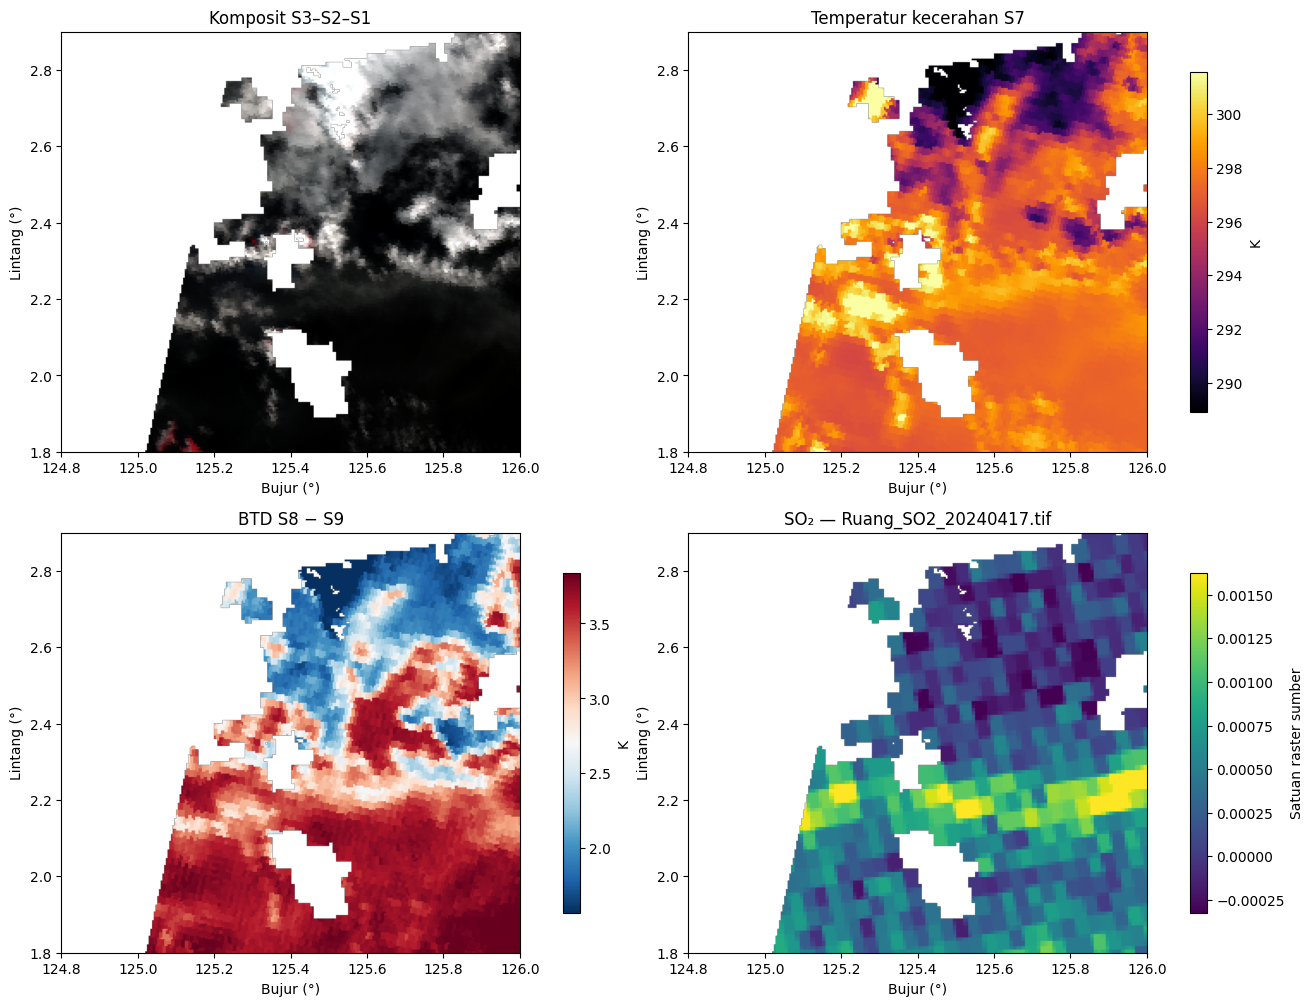

JUMLAH PIKSEL VALID: 38417

STATISTIK INPUT
 S1: min=0.0813512, P5=0.0901712, median=0.145609, P95=0.661626, max=1.06066
 S2: min=0.0373767, P5=0.0483507, median=0.10593, P95=0.646202, max=1.0615
 S3: min=0.0112274, P5=0.0226974, median=0.0840396, P95=0.698677, max=1.10917
 S7: min=272.79, P5=290.69, median=297.19, P95=299.87, max=309.37
 S8: min=259.76, P5=284.36, median=289.17, P95=290.46, max=291.27
 S9: min=259.44, P5=282.59, median=285.79, P95=286.7, max=287.34
BTD: min=0, P5=1.77002, median=3.35001, P95=3.78998, max=4.08002
SO2: min=-0.00051627, P5=-0.000210271, median=0.000326827, P95=0.00125439, max=0.00223313

Peta ini untuk memeriksa pola input, belum merupakan hasil klasifikasi CNN.


In [32]:
# ============================================================
# CELL 11 — PEMERIKSAAN SPASIAL INPUT KLASIFIKASI PRODUK ERUPSI
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from rasterio.transform import array_bounds

required = [
    "input_8band", "valid_input",
    "stack_transform", "SO2_PATH"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Jalankan Cell 10 terlebih dahulu. Belum tersedia: "
        + ", ".join(missing)
    )

if input_8band.shape[0] != 8:
    raise ValueError("Input harus memiliki delapan kanal.")

if not valid_input.any():
    raise ValueError("Tidak ada piksel valid gabungan.")

height, width = valid_input.shape

west, south, east, north = array_bounds(
    height, width, stack_transform
)

extent = [west, east, south, north]

# Urutan input:
# 0 S1, 1 S2, 2 S3, 3 S7, 4 S8, 5 S9, 6 BTD, 7 SO2

# Komposit inframerah dekat–merah–hijau.
# Ini bukan komposit warna alami.
rgb = np.moveaxis(
    input_8band[[2, 1, 0]],
    0, -1
).copy()

for channel in range(3):
    values = rgb[:, :, channel][valid_input]
    low, high = np.percentile(values, [2, 98])

    if high > low:
        rgb[:, :, channel] = np.clip(
            (rgb[:, :, channel] - low) / (high - low),
            0, 1
        )
    else:
        rgb[:, :, channel] = 0

rgb[~valid_input] = 0

# Transparansi untuk piksel tanpa seluruh input
rgba = np.dstack([
    rgb,
    valid_input.astype("float32")
])

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10),
    constrained_layout=True
)

axes[0, 0].imshow(
    rgba, extent=extent, origin="upper"
)
axes[0, 0].set_title("Komposit S3–S2–S1")

panels = [
    (axes[0, 1], 3, "Temperatur kecerahan S7", "inferno", "K"),
    (axes[1, 0], 6, "BTD S8 − S9", "RdBu_r", "K"),
    (axes[1, 1], 7, "SO₂ — " + SO2_PATH.name,
     "viridis", "Satuan raster sumber")
]

for ax, index, title, cmap, unit in panels:
    array = np.ma.masked_where(
        ~valid_input,
        input_8band[index]
    )

    values = input_8band[index][valid_input]
    low, high = np.percentile(values, [2, 98])

    if high <= low:
        high = low + 1e-6

    # Skala persentil hanya untuk tampilan.
    # Nilai data asli tidak dipotong atau diubah.
    im = ax.imshow(
        array,
        extent=extent,
        origin="upper",
        cmap=cmap,
        vmin=low,
        vmax=high
    )

    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8, label=unit)

for ax in axes.flat:
    ax.set_xlabel("Bujur (°)")
    ax.set_ylabel("Lintang (°)")

plt.show()

print("JUMLAH PIKSEL VALID:", int(valid_input.sum()))
print("\nSTATISTIK INPUT")

names = ["S1", "S2", "S3", "S7", "S8", "S9", "BTD", "SO2"]

for i, name in enumerate(names):
    values = input_8band[i][valid_input]
    percentiles = np.percentile(values, [5, 50, 95])

    print(
        f"{name:>3}: "
        f"min={values.min():.6g}, "
        f"P5={percentiles[0]:.6g}, "
        f"median={percentiles[1]:.6g}, "
        f"P95={percentiles[2]:.6g}, "
        f"max={values.max():.6g}"
    )

print(
    "\nPeta ini untuk memeriksa pola input, "
    "belum merupakan hasil klasifikasi CNN."
)

In [33]:
# ============================================================
# CELL 12 — LABEL REFERENSI BERBASIS ATURAN
# ============================================================

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from rasterio.transform import xy

OUT = Path(
    "/content/drive/MyDrive/Mount_Ruang_Final_2024/"
    "04_CNN_Sentinel3/Analisis_20240417"
)
OUT.mkdir(parents=True, exist_ok=True)

if "input_8band" not in globals():
    raise RuntimeError("Jalankan Cell 10 terlebih dahulu.")

S1, S2, S3, S7, S8, S9, BTD, SO2 = input_8band
valid = valid_input & np.all(np.isfinite(input_8band), axis=0)

if not valid.any():
    raise ValueError("Tidak ada input valid.")

# Kelas 255 dipertahankan sebagai NoData.
CLASS_NAMES = [
    "Ash candidate",
    "SO2-rich candidate",
    "Mixed candidate",
    "Meteorological cloud candidate",
    "Sea/background"
]
COLORS = ["#d73027", "#fdae61", "#984ea3", "#a6cee3", "#2166ac"]

PARAMS = {
    "BTD_ASH": -0.3,
    "BTD_SEED": -0.7,
    "MIN_ASH_PIXELS": 6,
    "MIN_ASH_SEEDS": 2,
    "ASH_DISTANCE_KM": 30.0,
    "SO2_PERCENTILE": 95,
    "SO2_SIGMA": 3.0,
    "MIN_SO2_PIXELS": 10,
    "CLOUD_BRIGHT": 0.25,
    "CLOUD_SOFT": 0.12,
    "CLOUD_COLD_DELTA": 10.0
}

# Jarak dari koordinat piksel ke Gunung Ruang
rr, cc = np.indices(valid.shape)
lon, lat = xy(stack_transform, rr.ravel(), cc.ravel(), offset="center")
lon = np.asarray(lon).reshape(valid.shape)
lat = np.asarray(lat).reshape(valid.shape)

volcano_lon, volcano_lat = 125.374, 2.303
p1, p2 = np.radians(lat), np.radians(volcano_lat)
dp = p1 - p2
dl = np.radians(lon - volcano_lon)
a = np.sin(dp / 2)**2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2)**2
distance_km = 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

structure = np.ones((3, 3), dtype=np.uint8)

# Kandidat abu: kelompok BTD negatif dengan benih dan konteks kawah
components, count = ndimage.label(
    valid & (BTD < PARAMS["BTD_ASH"]), structure
)
ash = np.zeros(valid.shape, dtype=bool)

for component_id in range(1, count + 1):
    component = components == component_id
    enough_pixels = component.sum() >= PARAMS["MIN_ASH_PIXELS"]
    enough_seeds = (
        np.sum(component & (BTD < PARAMS["BTD_SEED"]))
        >= PARAMS["MIN_ASH_SEEDS"]
    )
    near_volcano = np.any(
        component & (distance_km <= PARAMS["ASH_DISTANCE_KM"])
    )
    if enough_pixels and enough_seeds and near_volcano:
        ash |= component

# Inti SO2: persentil dan sebaran robust, tanpa mengubah unit asli
values = SO2[valid]
median_so2 = float(np.median(values))
robust_sigma = float(
    1.4826 * np.median(np.abs(values - median_so2))
)
SO2_THRESHOLD = max(
    float(np.percentile(values, PARAMS["SO2_PERCENTILE"])),
    median_so2 + PARAMS["SO2_SIGMA"] * robust_sigma,
    0.0
)

so2_raw = valid & (SO2 >= SO2_THRESHOLD) & (SO2 > 0)
components, count = ndimage.label(so2_raw, structure)
sizes = np.bincount(components.ravel())
keep = np.flatnonzero(sizes >= PARAMS["MIN_SO2_PIXELS"])
keep = keep[keep != 0]
so2_core = np.isin(components, keep)

# Referensi temperatur dari piksel relatif gelap
dark_limit = np.percentile(S2[valid], 40)
dark_pixels = valid & (S2 <= dark_limit) & (BTD >= -0.3)

if not dark_pixels.any():
    raise RuntimeError("Tidak ada piksel untuk referensi temperatur latar.")

background_bt = float(np.median(S8[dark_pixels]))

cloud = valid & (BTD >= -0.3) & (
    (S2 >= PARAMS["CLOUD_BRIGHT"])
    | (
        (S2 >= PARAMS["CLOUD_SOFT"])
        & (S8 < background_bt - PARAMS["CLOUD_COLD_DELTA"])
    )
)

# Prioritas Mixed > Ash > SO2 > Cloud > background
labels = np.full(valid.shape, 255, dtype=np.uint8)
labels[valid] = 4
labels[cloud] = 3
labels[so2_core & ~ash] = 1
labels[ash & ~so2_core] = 0
labels[ash & so2_core] = 2

print("Ambang SO2, satuan file sumber:", SO2_THRESHOLD)
for i, name in enumerate(CLASS_NAMES):
    print(f"{i}: {name}: {int((labels == i).sum())} piksel")

print(
    "\nKelas kosong tidak dibuat secara artifisial. "
    "Sea/background dapat mencakup daratan."
)

np.save(OUT / "reference_labels.npy", labels)

with open(OUT / "label_parameters.json", "w") as f:
    json.dump({
        **PARAMS,
        "SO2_THRESHOLD": SO2_THRESHOLD,
        "class_names": CLASS_NAMES,
        "reference_type": "rule_based_candidates",
        "so2_source": str(SO2_PATH),
        "stack_source": str(STACK_PATH)
    }, f, indent=2)

Ambang SO2, satuan file sumber: 0.001589336694451049
0: Ash candidate: 0 piksel
1: SO2-rich candidate: 852 piksel
2: Mixed candidate: 0 piksel
3: Meteorological cloud candidate: 11769 piksel
4: Sea/background: 25796 piksel

Kelas kosong tidak dibuat secara artifisial. Sea/background dapat mencakup daratan.


In [34]:
# ============================================================
# CELL 13 — PATCH 11x11 DAN PEMBAGIAN BLOK SPASIAL
# ============================================================

PATCH = 11
HALF = PATCH // 2
BLOCK = 44
STRIDE = 2
SEED = 42

rng = np.random.default_rng(SEED)
H, W = valid.shape

# Hanya pusat dengan seluruh patch memiliki input valid
patch_valid = ndimage.minimum_filter(
    valid.astype(np.uint8),
    size=PATCH,
    mode="constant",
    cval=0
).astype(bool)

rows, cols = np.where(patch_valid & (labels != 255))

# Sampling pusat patch dengan interval tetap
selected = (rows % STRIDE == 0) & (cols % STRIDE == 0)
rows, cols = rows[selected], cols[selected]

# Patch harus sepenuhnya berada dalam bloknya sendiri
inside = (
    (rows % BLOCK >= HALF)
    & (rows % BLOCK < BLOCK - HALF)
    & (cols % BLOCK >= HALF)
    & (cols % BLOCK < BLOCK - HALF)
)
rows, cols = rows[inside], cols[inside]

n_block_cols = int(np.ceil(W / BLOCK))
groups = (rows // BLOCK) * n_block_cols + cols // BLOCK
unique_groups = np.unique(groups)

if unique_groups.size < 6:
    raise RuntimeError(
        "Blok valid terlalu sedikit untuk pembagian spasial. "
        "Perlu meninjau cakupan data; jangan mengganti ke split piksel acak."
    )

# Pembagian tetap: tidak mencari split berdasarkan skor model
rng.shuffle(unique_groups)
n_test = max(1, int(np.ceil(0.2 * len(unique_groups))))
n_val = max(1, int(np.ceil(0.2 * len(unique_groups))))

test_groups = unique_groups[:n_test]
val_groups = unique_groups[n_test:n_test + n_val]
train_groups = unique_groups[n_test + n_val:]

indices = {
    "train": np.flatnonzero(np.isin(groups, train_groups)),
    "val": np.flatnonzero(np.isin(groups, val_groups)),
    "test": np.flatnonzero(np.isin(groups, test_groups))
}

cube = np.moveaxis(input_8band, 0, -1)

def make_dataset(index):
    patches = np.stack([
        cube[
            rows[j] - HALF:rows[j] + HALF + 1,
            cols[j] - HALF:cols[j] + HALF + 1
        ]
        for j in index
    ]).astype("float32")

    targets = labels[rows[index], cols[index]].astype("int32")
    return patches, targets

for name, index in indices.items():
    if not len(index):
        raise RuntimeError(f"Kelompok {name} tidak memiliki patch.")

X_train, y_train = make_dataset(indices["train"])
X_val, y_val = make_dataset(indices["val"])
X_test, y_test = make_dataset(indices["test"])

ACTIVE_CLASSES = np.unique(labels[valid]).astype(int)
train_classes = np.unique(y_train)

missing_train = set(ACTIVE_CLASSES) - set(train_classes)
if missing_train:
    raise RuntimeError(
        f"Kelas {sorted(missing_train)} tidak ada di data latih. "
        "Perlu tambahan sampel/blok atau citra yang relevan. "
        "Jangan membuat sampel kelas tersebut secara palsu."
    )

if len(train_classes) < 2:
    raise RuntimeError("Pelatihan klasifikasi membutuhkan minimal dua kelas.")

# Statistik normalisasi HANYA berasal dari data latih
mean = X_train.mean(axis=(0, 1, 2), keepdims=True)
std = X_train.std(axis=(0, 1, 2), keepdims=True)
std = np.maximum(std, 1e-6)

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std
X_test = (X_test - mean) / std

for name, y in [
    ("Train", y_train), ("Validation", y_val), ("Test", y_test)
]:
    print(name, len(y), "patch; kelas:", np.bincount(y, minlength=5))

np.savez_compressed(
    OUT / "normalization_and_split.npz",
    mean=mean,
    std=std,
    rows=rows,
    cols=cols,
    groups=groups,
    train_index=indices["train"],
    val_index=indices["val"],
    test_index=indices["test"],
    active_classes=ACTIVE_CLASSES
)

Train 2143 patch; kelas: [   0  152    0  590 1401]
Validation 1483 patch; kelas: [   0    0    0  380 1103]
Test 962 patch; kelas: [  0   0   0 302 660]


In [35]:
# ============================================================
# CELL 14 — TRAINING CNN
# ============================================================

import tensorflow as tf
import pandas as pd

tf.keras.utils.set_random_seed(SEED)

# Pemetaan hanya untuk kelas yang benar-benar tersedia
class_to_model = {
    int(class_id): i for i, class_id in enumerate(ACTIVE_CLASSES)
}

def encode(y):
    return np.array(
        [class_to_model[int(value)] for value in y],
        dtype=np.int32
    )

yt = encode(y_train)
yv = encode(y_val)
ye = encode(y_test)
N_CLASSES = len(ACTIVE_CLASSES)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(PATCH, PATCH, 8)),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(N_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

counts = np.bincount(yt, minlength=N_CLASSES)
class_weight = {
    i: float(len(yt) / (N_CLASSES * counts[i]))
    for i in range(N_CLASSES)
}

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        str(OUT / "cnn_best.keras"),
        monitor="val_loss",
        save_best_only=True
    ),
    tf.keras.callbacks.CSVLogger(str(OUT / "training_log.csv"))
]

model.summary()

history = model.fit(
    X_train, yt,
    validation_data=(X_val, yv),
    epochs=40,
    batch_size=64,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

model.save(str(OUT / "cnn_final.keras"))
pd.DataFrame(history.history).to_csv(
    OUT / "training_history.csv", index=False
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 11, 11, 32)     │         2,336 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 5, 5, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 5, 5, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,115 (242.64 KB)

 Trainable params: 62,115 (242.64 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.8390 - loss: 0.4289 - val_accuracy: 0.9353 - val_loss: 0.1676
Epoch 2/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8917 - loss: 0.2133 - val_accuracy: 0.9420 - val_loss: 0.1597
Epoch 3/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9085 - loss: 0.1764 - val_accuracy: 0.9299 - val_loss: 0.1861
Epoch 4/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 0.9146 - loss: 0.1612 - val_accuracy: 0.9373 - val_loss: 0.1749
Epoch 5/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.9127 - loss: 0.1598 - val_accuracy: 0.9461 - val_loss: 0.1594
Epoch 6/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9253 - loss: 0.1442 - val_accuracy: 0.9474 - val_loss: 0.1505
Epoch 7/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9277 - loss: 0.1315 - val_accuracy: 0.9454 - val_loss: 0.1577
Epoch 8/40
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9309 - loss: 0.1350 - val_accuracy: 0.9481 - v

,precision,recall,f1-score,support
SO2-rich candidate,0.000000,0.000000,0.000000,0.000000
Meteorological cloud candidate,0.956954,0.956954,0.956954,302.000000
Sea/background,0.980303,0.980303,0.980303,660.000000
accuracy,0.972973,0.972973,0.972973,0.972973
macro avg,0.645752,0.645752,0.645752,962.000000
weighted avg,0.972973,0.972973,0.972973,962.000000


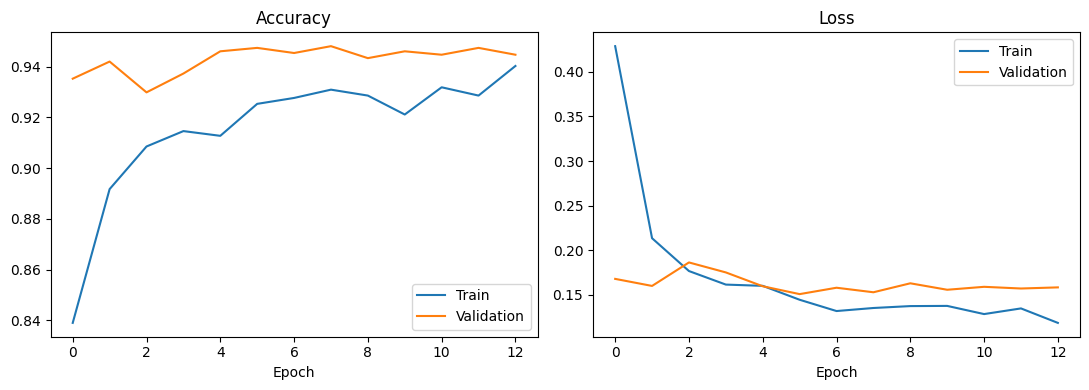

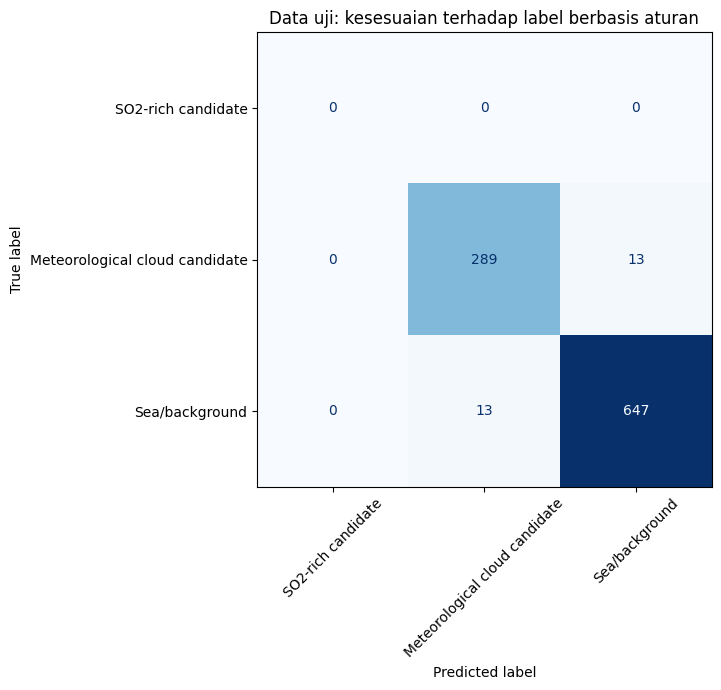

Test accuracy: 97.30%
Macro F1: 0.6458
Kelas tanpa sampel uji: ['SO2-rich candidate']
Skor ini bukan validasi independen deteksi produk erupsi.


In [36]:
# ============================================================
# CELL 15 — EVALUASI DATA UJI
# ============================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

prob_test = model.predict(X_test, batch_size=256, verbose=0)
pred_test = ACTIVE_CLASSES[np.argmax(prob_test, axis=1)]

active_names = [CLASS_NAMES[i] for i in ACTIVE_CLASSES]

report = classification_report(
    y_test,
    pred_test,
    labels=ACTIVE_CLASSES,
    target_names=active_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
display(report_df)
report_df.to_csv(OUT / "classification_report.csv")

cm = confusion_matrix(
    y_test, pred_test, labels=ACTIVE_CLASSES
)

pd.DataFrame(
    cm, index=active_names, columns=active_names
).to_csv(OUT / "confusion_matrix.csv")

accuracy = float(accuracy_score(y_test, pred_test))
macro_f1 = float(f1_score(
    y_test,
    pred_test,
    labels=ACTIVE_CLASSES,
    average="macro",
    zero_division=0
))

metrics = {
    "test_accuracy": accuracy,
    "macro_f1_over_active_classes": macro_f1,
    "test_patches": int(len(y_test)),
    "reference": "rule_based_labels",
    "classes_without_test_samples": [
        CLASS_NAMES[i]
        for i in ACTIVE_CLASSES if not np.any(y_test == i)
    ]
}

with open(OUT / "test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()

fig.tight_layout()
fig.savefig(OUT / "training_curves.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=active_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
ax.set_title("Data uji: kesesuaian terhadap label berbasis aturan")
fig.tight_layout()
fig.savefig(OUT / "confusion_matrix.png", dpi=200)
plt.show()

print(f"Test accuracy: {accuracy:.2%}")
print(f"Macro F1: {macro_f1:.4f}")
print("Kelas tanpa sampel uji:", metrics["classes_without_test_samples"])
print("Skor ini bukan validasi independen deteksi produk erupsi.")

In [37]:
# ============================================================
# CELL 16 — PREDIKSI DAN EKSPOR GEOTIFF
# ============================================================

import rasterio

pred_map = np.full((H, W), 255, dtype=np.uint8)
confidence_map = np.full((H, W), -9999, dtype=np.float32)

prediction_rows, prediction_cols = np.where(patch_valid)
BATCH = 512

for start in range(0, len(prediction_rows), BATCH):
    r = prediction_rows[start:start + BATCH]
    c = prediction_cols[start:start + BATCH]

    batch = np.stack([
        cube[
            row - HALF:row + HALF + 1,
            col - HALF:col + HALF + 1
        ]
        for row, col in zip(r, c)
    ]).astype("float32")

    batch = (batch - mean) / std
    probabilities = model.predict(batch, verbose=0)

    pred_map[r, c] = ACTIVE_CLASSES[
        np.argmax(probabilities, axis=1)
    ]
    confidence_map[r, c] = probabilities.max(axis=1)

profile = {
    "driver": "GTiff",
    "height": H,
    "width": W,
    "count": 1,
    "crs": stack_crs,
    "transform": stack_transform,
    "compress": "deflate"
}

with rasterio.open(
    OUT / "CNN_classification.tif",
    "w", **profile, dtype="uint8", nodata=255
) as dst:
    dst.write(pred_map, 1)
    dst.set_band_description(1, "CNN_rule_based_candidate_class")
    dst.update_tags(
        class_names=json.dumps(CLASS_NAMES),
        reference_type="rule_based",
        nodata_meaning="No complete valid 11x11 input patch"
    )

with rasterio.open(
    OUT / "CNN_confidence.tif",
    "w", **profile, dtype="float32", nodata=-9999
) as dst:
    dst.write(confidence_map, 1)
    dst.set_band_description(1, "Maximum_softmax_probability")

with rasterio.open(
    OUT / "reference_classification.tif",
    "w", **profile, dtype="uint8", nodata=255
) as dst:
    dst.write(labels, 1)

print("Prediksi selesai.")
print("Piksel terklasifikasi:", int((pred_map != 255).sum()))
print("Lokasi hasil:", OUT)

Prediksi selesai.
Piksel terklasifikasi: 29862
Lokasi hasil: /content/drive/MyDrive/Mount_Ruang_Final_2024/04_CNN_Sentinel3/Analisis_20240417


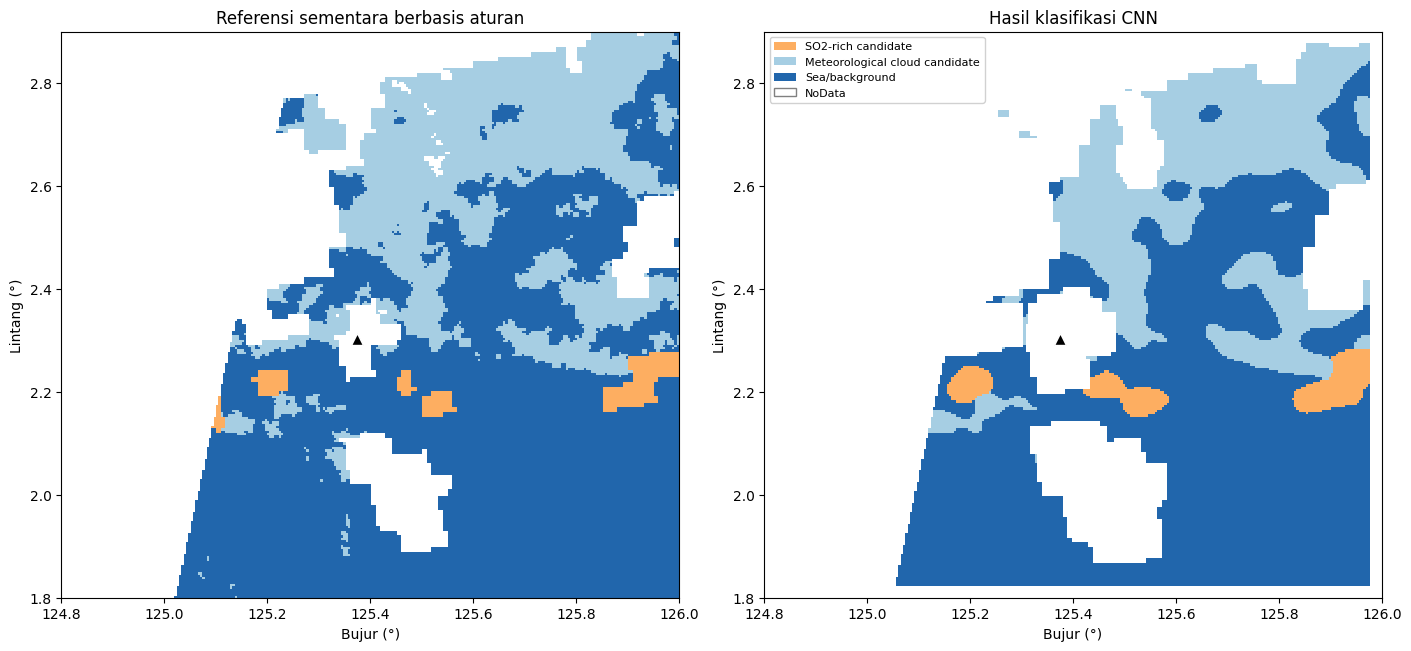

,class_id,class_name,reference_pixels,predicted_pixels
0,0,Ash candidate,0,0
1,1,SO2-rich candidate,852,1159
2,2,Mixed candidate,0,0
3,3,Meteorological cloud candidate,11769,8610
4,4,Sea/background,25796,20093



 JAWABAN SOAL NOMOR 4

Klasifikasi kandidat produk erupsi Gunung Ruang dilakukan menggunakan CNN pada Google Colab. Input terdiri atas kanal Sentinel-3 SLSTR S1, S2, S3, S7, S8, S9, BTD S8-S9, dan raster SO2 Sentinel-5P yang diselaraskan ke grid SLSTR. Label referensi dibentuk menggunakan aturan spektral dan statistik. Patch berukuran 11 x 11 piksel dibagi berdasarkan blok spasial menjadi data latih, validasi, dan uji; patch yang melintasi batas blok tidak digunakan. Pada 962 patch uji, accuracy mencapai 97.30% dan macro F1 sebesar 0.6458. Nilai tersebut menunjukkan kesesuaian CNN terhadap label berbasis aturan, bukan akurasi terhadap ground truth independen. Kelas tanpa sampel uji belum dapat dinilai kinerjanya. Kelas Sea/background dapat mencakup daratan. Ketidaksesuaian waktu lintasan, awan, resolusi asli sensor, dan ketidakpastian label membatasi interpretasi hasil. Peta penuh memuat wilayah latih maupun uji; metrik evaluasi dihitung hanya dari patch uji.

Seluruh keluaran disimpa

In [39]:
# ============================================================
# CELL 17 — PETA DAN RINGKASAN HASIL
# ============================================================
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from rasterio.transform import array_bounds

west, south, east, north = array_bounds(H, W, stack_transform)
extent = [west, east, south, north]

cmap = ListedColormap(COLORS)
cmap.set_bad("white")
norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), cmap.N)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 7), constrained_layout=True
)

for ax, array, title in [
    (axes[0], labels, "Referensi sementara berbasis aturan"),
    (axes[1], pred_map, "Hasil klasifikasi CNN")
]:
    masked = np.ma.masked_where(array == 255, array)

    ax.imshow(
        masked, extent=extent, origin="upper",
        cmap=cmap, norm=norm, interpolation="nearest"
    )
    ax.plot(
        125.374, 2.303, "^", color="black",
        markeredgecolor="white", markersize=9
    )
    ax.set_title(title)
    ax.set_xlabel("Bujur (°)")
    ax.set_ylabel("Lintang (°)")

handles = [
    Patch(facecolor=COLORS[i], label=CLASS_NAMES[i])
    for i in ACTIVE_CLASSES
]
handles.append(Patch(facecolor="white", edgecolor="gray", label="NoData"))

axes[1].legend(
    handles=handles, loc="upper left",
    fontsize=8, framealpha=0.9
)

fig.savefig(OUT / "CNN_classification_map.png", dpi=250)
plt.show()

# Ringkasan jumlah piksel, bukan luas berbasis perkiraan 500 m
summary = pd.DataFrame([
    {
        "class_id": i,
        "class_name": CLASS_NAMES[i],
        "reference_pixels": int((labels == i).sum()),
        "predicted_pixels": int((pred_map == i).sum())
    }
    for i in range(5)
])
display(summary)
summary.to_csv(OUT / "class_pixel_counts.csv", index=False)

answer = (
    "Klasifikasi kandidat produk erupsi Gunung Ruang dilakukan "
    "menggunakan CNN pada Google Colab. Input terdiri atas kanal "
    "Sentinel-3 SLSTR S1, S2, S3, S7, S8, S9, BTD S8-S9, "
    "dan raster SO2 Sentinel-5P yang diselaraskan ke grid SLSTR. "
    "Label referensi dibentuk menggunakan aturan spektral dan "
    "statistik. Patch berukuran 11 x 11 piksel dibagi berdasarkan "
    "blok spasial menjadi data latih, validasi, dan uji; patch "
    "yang melintasi batas blok tidak digunakan. "
    f"Pada {len(y_test)} patch uji, accuracy mencapai "
    f"{accuracy:.2%} dan macro F1 sebesar {macro_f1:.4f}. "
    "Nilai tersebut menunjukkan kesesuaian CNN terhadap label "
    "berbasis aturan, bukan akurasi terhadap ground truth independen. "
    "Kelas tanpa sampel uji belum dapat dinilai kinerjanya. "
    "Kelas Sea/background dapat mencakup daratan. "
    "Ketidaksesuaian waktu lintasan, awan, resolusi asli sensor, "
    "dan ketidakpastian label membatasi interpretasi hasil. "
    "Peta penuh memuat wilayah latih maupun uji; metrik evaluasi "
    "dihitung hanya dari patch uji."
)

print("\n JAWABAN SOAL NOMOR 4\n")
print(answer)

with open(OUT / "ringkasan_jawaban_nomor_4.txt", "w") as f:
    f.write(answer)

print("\nSeluruh keluaran disimpan di:", OUT)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 35.0 MB/s eta 0:00:00


,class_id,class_name,pixels
0,1,Ash,0
1,2,SO2-rich,24146
2,3,Mixed Ash + SO2,0
3,4,Meteorological Cloud,175958
4,5,Sea,214250


Ambang SO2: 0.032578278332948685
Label ini kandidat berbasis aturan, perlu pemeriksaan visual.


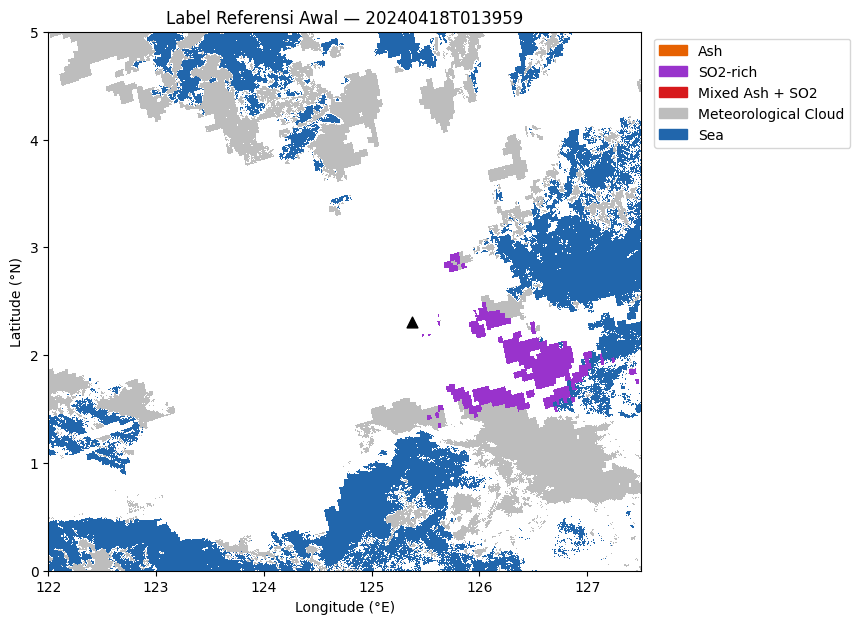

In [ ]:
# 9. Menyusun label referensi awal
!pip -q install scipy scikit-learn global-land-mask

from scipy import ndimage
from global_land_mask import globe
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

CLASS_NAMES = [
    "Ash", "SO2-rich", "Mixed Ash + SO2",
    "Meteorological Cloud", "Sea"
]
CLASS_COLORS = [
    "#e66101", "#9933cc", "#d7191c",
    "#bdbdbd", "#2166ac"
]

s1, s2, s3, s7, s8, s9, btd = stack

rows, cols = np.indices((NY, NX))
lon = transform.c + (cols + 0.5) * transform.a
lat = transform.f + (rows + 0.5) * transform.e

distance_km = np.sqrt(
    ((lon - VOLCANO_LON) * 111.32
     * np.cos(np.deg2rad(VOLCANO_LAT))) ** 2
    + ((lat - VOLCANO_LAT) * 110.57) ** 2
)

# Membatasi label pada lokasi dengan kedua data tersedia.
joint_valid = valid & np.isfinite(so2)
ocean = globe.is_ocean(lat, lon)

# Kandidat abu: kelompok BTD negatif dengan benih kuat
# dan setidaknya satu piksel dekat gunung.
candidate = valid & (btd < -0.3)
seed = valid & (btd < -0.7)

components, n_components = ndimage.label(
    candidate, structure=np.ones((3, 3))
)

ash = np.zeros((NY, NX), dtype=bool)

if n_components:
    ids = np.arange(1, n_components + 1)
    sizes = ndimage.sum(candidate, components, ids)
    seeds = ndimage.sum(seed, components, ids)
    nearest = ndimage.minimum(distance_km, components, ids)

    keep = ids[
        (sizes >= 6) & (seeds >= 2) & (nearest <= 30)
    ]
    ash = np.isin(components, keep)

# Ambang SO2 mengikuti pendekatan persentil dan sebaran robust.
positive_so2 = so2[joint_valid & (so2 > 0)]

if positive_so2.size < 10:
    raise RuntimeError(
        "Data SO2 positif terlalu sedikit untuk menyusun label."
    )

median_so2 = float(np.median(positive_so2))
mad_so2 = float(
    1.4826 * np.median(np.abs(positive_so2 - median_so2))
)
so2_threshold = max(
    float(np.percentile(positive_so2, 95)),
    median_so2 + 3 * mad_so2
)

so2_core = joint_valid & (so2 > so2_threshold)
lab, number = ndimage.label(
    so2_core, structure=np.ones((3, 3))
)

if number:
    ids = np.arange(1, number + 1)
    sizes = ndimage.sum(so2_core, lab, ids)
    so2_core = np.isin(lab, ids[sizes >= 10])

# Referensi suhu laut dari piksel laut yang relatif gelap.
sea_pool = valid & ocean & (btd >= -0.3)
if not sea_pool.any():
    raise RuntimeError("Piksel referensi laut tidak tersedia.")

dark_limit = np.percentile(s2[sea_pool], 40)
sea_ref = sea_pool & (s2 <= dark_limit)
sea_bt = float(np.median(s8[sea_ref]))

cloud = (
    ((s2 >= 0.25)
     | ((s2 >= 0.12) & (s8 < sea_bt - 10)))
    & (btd >= -0.3)
)

# Laut dibatasi mask laut dan reflektansi rendah.
sea = (
    ocean & (s3 < 0.08) & (s2 < 0.12)
    & (btd >= -0.3) & ~cloud
)

# 0 = tidak berlabel; 1–5 = kelas referensi.
labels = np.zeros((NY, NX), dtype="uint8")
labels[joint_valid & sea] = 5
labels[joint_valid & cloud] = 4
labels[joint_valid & so2_core] = 2
labels[joint_valid & ash] = 1
labels[joint_valid & ash & so2_core] = 3

counts = pd.DataFrame({
    "class_id": np.arange(1, 6),
    "class_name": CLASS_NAMES,
    "pixels": [(labels == k).sum() for k in range(1, 6)]
})
display(counts)
counts.to_csv(OUTPUT / f"Reference_Counts_{tag}.csv", index=False)

print("Ambang SO2:", so2_threshold)
print("Label ini kandidat berbasis aturan, perlu pemeriksaan visual.")

class_cmap = ListedColormap(["white"] + CLASS_COLORS)
class_norm = BoundaryNorm(np.arange(-0.5, 6.5), 6)

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(
    labels, extent=extent, origin="upper",
    cmap=class_cmap, norm=class_norm,
    interpolation="nearest"
)
ax.scatter(
    VOLCANO_LON, VOLCANO_LAT,
    marker="^", color="black", s=60
)
ax.set_title("Label Referensi Awal — " + tag)
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.legend(
    handles=[Patch(color=c, label=n)
             for c, n in zip(CLASS_COLORS, CLASS_NAMES)],
    loc="upper left", bbox_to_anchor=(1.01, 1)
)
fig.savefig(
    OUTPUT / f"Reference_Map_{tag}.png",
    dpi=250, bbox_inches="tight"
)
plt.show()

with rasterio.open(
    OUTPUT / f"Reference_Labels_{tag}.tif",
    "w", driver="GTiff", height=NY, width=NX,
    count=1, dtype="uint8", crs="EPSG:4326",
    transform=transform, nodata=0, compress="deflate"
) as dst:
    dst.write(labels, 1)

In [ ]:
# 10. Membagi sampel latih, validasi, dan uji
from sklearn.preprocessing import StandardScaler

SEED = 42
rng = np.random.default_rng(SEED)
PATCH = 11
HALF = PATCH // 2
BLOCK = 64

features = np.moveaxis(stack, 0, -1).astype("float32")
feature_valid = np.isfinite(features).all(axis=-1)

patch_valid = ndimage.minimum_filter(
    feature_valid.astype("uint8"),
    size=PATCH, mode="constant", cval=0
).astype(bool)

# Patch harus seluruhnya berada di dalam bloknya.
inside_block = (
    (rows % BLOCK >= HALF)
    & (rows % BLOCK < BLOCK - HALF)
    & (cols % BLOCK >= HALF)
    & (cols % BLOCK < BLOCK - HALF)
)

n_block_cols = int(np.ceil(NX / BLOCK))
block_id = (rows // BLOCK) * n_block_cols + cols // BLOCK

eligible = (labels > 0) & patch_valid & inside_block
groups = np.unique(block_id[eligible])
groups = rng.permutation(groups)

if len(groups) < 5:
    raise RuntimeError("Blok berlabel terlalu sedikit untuk pembagian spasial.")

n_train = max(1, int(0.6 * len(groups)))
n_val = max(1, int(0.2 * len(groups)))

train_groups = groups[:n_train]
val_groups = groups[n_train:n_train + n_val]
test_groups = groups[n_train + n_val:]

split_map = np.zeros((NY, NX), dtype="uint8")
split_map[np.isin(block_id, train_groups)] = 1
split_map[np.isin(block_id, val_groups)] = 2
split_map[np.isin(block_id, test_groups)] = 3

availability = np.array([
    [np.sum(eligible & (labels == k) & (split_map == split))
     for split in (1, 2, 3)]
    for k in range(1, 6)
])

table = pd.DataFrame(
    availability, index=CLASS_NAMES,
    columns=["train", "validation", "test"]
)
display(table)
table.to_csv(OUTPUT / f"Spatial_Sample_Availability_{tag}.csv")

# Kelas harus tersedia pada ketiga kelompok.
active_ids = np.array([
    k for k in range(1, 6)
    if availability[k - 1].min() >= 30
], dtype=int)

if len(active_ids) < 2:
    raise RuntimeError(
        "Kurang dari dua kelas memiliki cukup sampel pada semua split. "
        "Periksa label atau gunakan citra tambahan; jangan memaksakan CNN."
    )

active_names = [CLASS_NAMES[k - 1] for k in active_ids]
print("Kelas yang dimodelkan:", active_names)
print(
    "Kelas tidak dimodelkan:",
    [CLASS_NAMES[k - 1] for k in range(1, 6)
     if k not in active_ids]
)

def sample_centres(split, cap):
    chosen = []
    for class_id in active_ids:
        positions = np.argwhere(
            eligible & (labels == class_id) & (split_map == split)
        )
        take = min(cap, len(positions))
        chosen.append(
            positions[rng.choice(len(positions), take, replace=False)]
        )
    result = np.concatenate(chosen)
    return result[rng.permutation(len(result))]

train_rc = sample_centres(1, 1500)
val_rc = sample_centres(2, 500)
test_rc = sample_centres(3, 500)

# Normalisasi dipelajari hanya dari wilayah latih.
scaler_pool = np.argwhere(feature_valid & (split_map == 1))
if len(scaler_pool) > 100000:
    scaler_pool = scaler_pool[
        rng.choice(len(scaler_pool), 100000, replace=False)
    ]

scaler = StandardScaler()
scaler.fit(features[scaler_pool[:, 0], scaler_pool[:, 1]])

features_norm = (
    (features - scaler.mean_) / scaler.scale_
).astype("float32")
features_norm[~feature_valid] = 0

def extract_patches(centres):
    return np.stack([
        features_norm[
            r-HALF:r+HALF+1,
            c-HALF:c+HALF+1
        ]
        for r, c in centres
    ])

def encode_labels(centres):
    values = labels[centres[:, 0], centres[:, 1]]
    return np.searchsorted(active_ids, values).astype("int32")

X_train, y_train = extract_patches(train_rc), encode_labels(train_rc)
X_val, y_val = extract_patches(val_rc), encode_labels(val_rc)
X_test, y_test = extract_patches(test_rc), encode_labels(test_rc)

np.savez(
    OUTPUT / f"CNN_Preprocessing_{tag}.npz",
    mean=scaler.mean_, scale=scaler.scale_,
    active_ids=active_ids, patch=PATCH
)
np.savez(
    OUTPUT / f"CNN_Sample_Locations_{tag}.npz",
    train_rc=train_rc, val_rc=val_rc, test_rc=test_rc,
    train_groups=train_groups,
    val_groups=val_groups, test_groups=test_groups
)

print("Ukuran data latih:", X_train.shape)
print("Ukuran data validasi:", X_val.shape)
print("Ukuran data uji:", X_test.shape)

,train,validation,test
Ash,0,0,0
SO2-rich,11684,754,3929
Mixed Ash + SO2,0,0,0
Meteorological Cloud,64664,28183,25439
Sea,85029,27729,33990


Kelas yang dimodelkan: ['SO2-rich', 'Meteorological Cloud', 'Sea']
Kelas tidak dimodelkan: ['Ash', 'Mixed Ash + SO2']
Ukuran data latih: (4500, 11, 11, 7)
Ukuran data validasi: (1500, 11, 11, 7)
Ukuran data uji: (1500, 11, 11, 7)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 11, 11, 32)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 5, 5, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,899 (97.26 KB)

 Trainable params: 24,899 (97.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
71/71 - 2s - 34ms/step - accuracy: 0.7798 - loss: 0.5403 - val_accuracy: 0.7587 - val_loss: 0.6617
Epoch 2/40
71/71 - 1s - 13ms/step - accuracy: 0.8598 - loss: 0.3455 - val_accuracy: 0.7613 - val_loss: 0.7151
Epoch 3/40
71/71 - 1s - 13ms/step - accuracy: 0.8787 - loss: 0.3044 - val_accuracy: 0.7727 - val_loss: 0.7112
Epoch 4/40
71/71 - 1s - 16ms/step - accuracy: 0.8922 - loss: 0.2788 - val_accuracy: 0.7867 - val_loss: 0.6604
Epoch 5/40
71/71 - 1s - 12ms/step - accuracy: 0.8967 - loss: 0.2657 - val_accuracy: 0.7900 - val_loss: 0.6701
Epoch 6/40
71/71 - 1s - 12ms/step - accuracy: 0.8984 - loss: 0.2598 - val_accuracy: 0.7887 - val_loss: 0.7277
Epoch 7/40
71/71 - 1s - 13ms/step - accuracy: 0.9047 - loss: 0.2449 - val_accuracy: 0.7960 - val_loss: 0.7437
Epoch 8/40
71/71 - 1s - 12ms/step - accuracy: 0.9142 - loss: 0.2269 - val_accuracy: 0.8113 - val_loss: 0.6950
Epoch 9/40
71/71 - 1s - 10ms/step - accuracy: 0.9111 - loss: 0.2196 - val_accuracy: 0.8100 - val_loss: 0.7103
Epoch 10/4

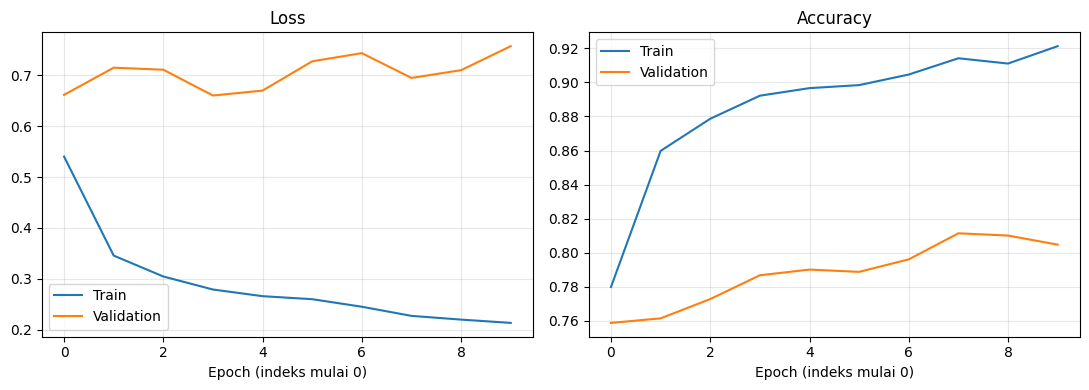

In [ ]:
# 11. Melatih model CNN
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

keras.utils.set_random_seed(SEED)

model = keras.Sequential([
    layers.Input(shape=(PATCH, PATCH, 7)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(active_ids), activation="softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(active_ids)),
    y=y_train
)
class_weights = dict(enumerate(weights))

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=64,
    class_weight=class_weights,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=6,
            restore_best_weights=True
        ),
        keras.callbacks.TerminateOnNaN()
    ],
    verbose=2
)

model.save(OUTPUT / f"Ruang_CNN_{tag}.keras")

history_df = pd.DataFrame(history.history)
history_df.to_csv(
    OUTPUT / f"CNN_Training_History_{tag}.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df["loss"], label="Train")
axes[0].plot(history_df["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[1].plot(history_df["accuracy"], label="Train")
axes[1].plot(history_df["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy")

for ax in axes:
    ax.set_xlabel("Epoch (indeks mulai 0)")
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(OUTPUT / f"CNN_Learning_Curves_{tag}.png", dpi=250)
plt.show()

,precision,recall,f1-score,support
SO2-rich,0.537572,0.186000,0.276374,500.000000
Meteorological Cloud,0.731419,0.866000,0.793040,500.000000
Sea,0.636735,0.936000,0.757895,500.000000
accuracy,0.662667,0.662667,0.662667,0.662667
macro avg,0.635242,0.662667,0.609103,1500.000000
weighted avg,0.635242,0.662667,0.609103,1500.000000


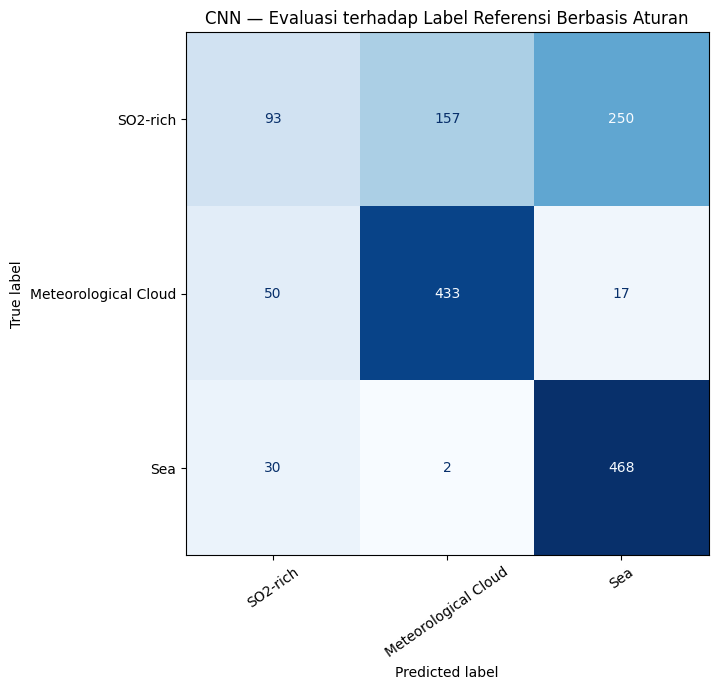

Accuracy sampel uji: 0.663
Macro F1 sampel uji: 0.609
Evaluasi menggunakan sampel seimbang per kelas dengan batas jumlah.
Ini kesesuaian terhadap label aturan, bukan validasi lapangan.

 Model CNN menggunakan patch 11 x 11 dan tujuh kanal SLSTR. Kelas yang dimodelkan: SO2-rich, Meteorological Cloud, Sea. Jumlah sampel latih/validasi/uji: 4500/1500/1500. Accuracy uji = 0.663; macro F1 = 0.609. Data dibagi berdasarkan blok spasial dengan patch tidak melintasi batas blok. Label dibentuk dari aturan BTD, reflektansi, dan SO2; evaluasi menunjukkan kesesuaian terhadap label tersebut, bukan akurasi terhadap ground truth independen. Perbedaan waktu perekaman SLSTR dan SO2 serta kekosongan data membatasi interpretasi.


In [ ]:
# 12. Mengevaluasi model pada sampel uji
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, accuracy_score, f1_score
)

test_probability = model.predict(X_test, batch_size=128, verbose=0)
test_prediction = test_probability.argmax(axis=1)

report = classification_report(
    y_test, test_prediction,
    labels=np.arange(len(active_ids)),
    target_names=active_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T
display(report_df)
report_df.to_csv(OUTPUT / f"CNN_Classification_Report_{tag}.csv")

accuracy = accuracy_score(y_test, test_prediction)
macro_f1 = f1_score(
    y_test, test_prediction, average="macro", zero_division=0
)

cm = confusion_matrix(
    y_test, test_prediction,
    labels=np.arange(len(active_ids))
)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=active_names
).plot(ax=ax, cmap="Blues", xticks_rotation=35, colorbar=False)

ax.set_title("CNN — Evaluasi terhadap Label Referensi Berbasis Aturan")
fig.tight_layout()
fig.savefig(
    OUTPUT / f"CNN_Confusion_Matrix_{tag}.png",
    dpi=250, bbox_inches="tight"
)
plt.show()

print(f"Accuracy sampel uji: {accuracy:.3f}")
print(f"Macro F1 sampel uji: {macro_f1:.3f}")
print("Evaluasi menggunakan sampel seimbang per kelas dengan batas jumlah.")
print("Ini kesesuaian terhadap label aturan, bukan validasi lapangan.")

summary = (
    f"Model CNN menggunakan patch {PATCH} x {PATCH} dan tujuh kanal SLSTR. "
    f"Kelas yang dimodelkan: {', '.join(active_names)}. "
    f"Jumlah sampel latih/validasi/uji: "
    f"{len(y_train)}/{len(y_val)}/{len(y_test)}. "
    f"Accuracy uji = {accuracy:.3f}; macro F1 = {macro_f1:.3f}. "
    "Data dibagi berdasarkan blok spasial dengan patch tidak melintasi "
    "batas blok. Label dibentuk dari aturan BTD, reflektansi, dan SO2; "
    "evaluasi menunjukkan kesesuaian terhadap label tersebut, bukan "
    "akurasi terhadap ground truth independen. Perbedaan waktu perekaman "
    "SLSTR dan SO2 serta kekosongan data membatasi interpretasi."
)

(OUTPUT / f"CNN_Evaluation_Summary_{tag}.txt").write_text(
    summary, encoding="utf-8"
)
print("\n", summary)

Diproses: 2048/517904
Diproses: 43008/517904
Diproses: 83968/517904
Diproses: 124928/517904
Diproses: 165888/517904
Diproses: 206848/517904
Diproses: 247808/517904
Diproses: 288768/517904
Diproses: 329728/517904
Diproses: 370688/517904
Diproses: 411648/517904
Diproses: 452608/517904
Diproses: 493568/517904


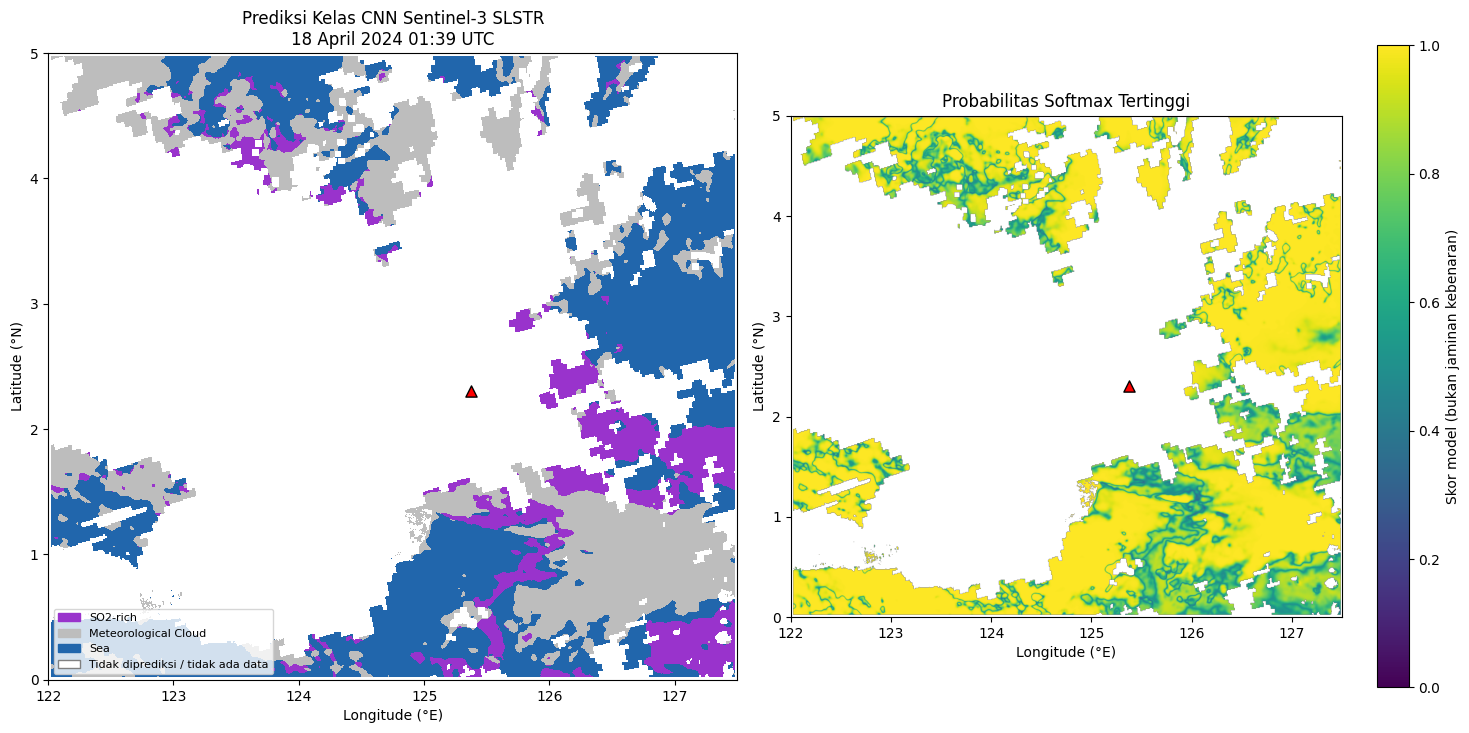

,class_id,class_name,predicted_pixels
0,2,SO2-rich,77673
1,4,Meteorological Cloud,182491
2,5,Sea,257740


Hasil tersimpan di: /content/drive/MyDrive/Mount_Ruang_Eruption_2024/04_CNN_Sentinel3
Peta prediksi mencakup wilayah latih, validasi, dan uji.
Kinerja generalisasi dilaporkan hanya dari sampel uji cell 12.


In [ ]:
# 13. Membuat dan menyimpan peta hasil klasifikasi CNN
prediction_domain = (
    joint_valid & patch_valid
    & (ocean | cloud | ash | so2_core)
)

prediction = np.zeros((NY, NX), dtype="uint8")
confidence = np.full((NY, NX), np.nan, dtype="float32")

centres = np.argwhere(prediction_domain)
CHUNK = 2048

for start in range(0, len(centres), CHUNK):
    batch_rc = centres[start:start + CHUNK]
    batch_x = extract_patches(batch_rc)

    probability = model.predict(
        batch_x, batch_size=128, verbose=0
    )
    class_index = probability.argmax(axis=1)

    rr, cc = batch_rc[:, 0], batch_rc[:, 1]
    prediction[rr, cc] = active_ids[class_index]
    confidence[rr, cc] = probability.max(axis=1)

    if start % (CHUNK * 20) == 0:
        print(f"Diproses: {min(start + CHUNK, len(centres))}/{len(centres)}")

for filename, array, dtype, nodata in [
    (f"Ruang_CNN_Classification_{tag}.tif", prediction, "uint8", 0),
    (f"Ruang_CNN_Confidence_{tag}.tif", confidence, "float32", np.nan)
]:
    with rasterio.open(
        OUTPUT / filename,
        "w", driver="GTiff",
        height=NY, width=NX, count=1,
        dtype=dtype, crs="EPSG:4326",
        transform=transform, nodata=nodata,
        compress="deflate"
    ) as dst:
        dst.write(array, 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(
    prediction, extent=extent, origin="upper",
    cmap=class_cmap, norm=class_norm,
    interpolation="nearest"
)
axes[0].set_title(
    "Prediksi Kelas CNN Sentinel-3 SLSTR\n"
    + acquisition.strftime("%d %B %Y %H:%M UTC")
)

legend_items = [
    Patch(color=CLASS_COLORS[k - 1], label=CLASS_NAMES[k - 1])
    for k in active_ids
]
legend_items.append(
    Patch(facecolor="white", edgecolor="gray",
          label="Tidak diprediksi / tidak ada data")
)
axes[0].legend(handles=legend_items, loc="lower left", fontsize=8)

im = axes[1].imshow(
    confidence, extent=extent, origin="upper",
    cmap="viridis", vmin=0, vmax=1
)
axes[1].set_title("Probabilitas Softmax Tertinggi")
fig.colorbar(im, ax=axes[1], label="Skor model (bukan jaminan kebenaran)")

for ax in axes:
    ax.scatter(
        VOLCANO_LON, VOLCANO_LAT,
        marker="^", color="red", edgecolors="black", s=65
    )
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")

fig.tight_layout()
fig.savefig(
    OUTPUT / f"Ruang_CNN_Final_Map_{tag}.png",
    dpi=250, bbox_inches="tight"
)
plt.show()

result_counts = pd.DataFrame({
    "class_id": active_ids,
    "class_name": active_names,
    "predicted_pixels": [
        int((prediction == k).sum()) for k in active_ids
    ]
})
result_counts.to_csv(
    OUTPUT / f"CNN_Prediction_Counts_{tag}.csv", index=False
)
display(result_counts)

print("Hasil tersimpan di:", OUTPUT)
print("Peta prediksi mencakup wilayah latih, validasi, dan uji.")
print("Kinerja generalisasi dilaporkan hanya dari sampel uji cell 12.")

In [ ]:
# 14. Menampilkan ringkasan hasil klasifikasi CNN
print("Tanggal citra:", acquisition.strftime("%d April %Y %H:%M UTC"))
print("Kelas yang dimodelkan:", ", ".join(active_names))
print("Jumlah sampel latih:", len(y_train))
print("Jumlah sampel validasi:", len(y_val))
print("Jumlah sampel uji:", len(y_test))
print(f"Accuracy uji: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro F1: {macro_f1:.4f}")

print("\nKinerja setiap kelas:")
display(
    report_df.loc[
        active_names,
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

print("\nJumlah piksel hasil prediksi:")
display(result_counts)

print("\nKelas yang tidak dimodelkan:")
excluded = [
    CLASS_NAMES[k - 1]
    for k in range(1, 6)
    if k not in active_ids
]
print(", ".join(excluded) if excluded else "Semua kelas dimodelkan.")

print("\nFolder hasil:", OUTPUT)

Tanggal citra: 18 April 2024 01:39 UTC
Kelas yang dimodelkan: SO2-rich, Meteorological Cloud, Sea
Jumlah sampel latih: 4500
Jumlah sampel validasi: 1500
Jumlah sampel uji: 1500
Accuracy uji: 0.6627 (66.27%)
Macro F1: 0.6091

Kinerja setiap kelas:


,precision,recall,f1-score,support
SO2-rich,0.5376,0.186,0.2764,500.0
Meteorological Cloud,0.7314,0.866,0.7930,500.0
Sea,0.6367,0.936,0.7579,500.0



Jumlah piksel hasil prediksi:


,class_id,class_name,predicted_pixels
0,2,SO2-rich,77673
1,4,Meteorological Cloud,182491
2,5,Sea,257740



Kelas yang tidak dimodelkan:
Ash, Mixed Ash + SO2

Folder hasil: /content/drive/MyDrive/Mount_Ruang_Eruption_2024/04_CNN_Sentinel3
